# TASK AIS-5 -- rank AIS vessel candidates (first task allowed to rank)

Uses `iste.ais_ranking` (new; reuses T35's own `renormalize_weighted_mean` utility
unchanged, the same reuse T36 itself already relies on -- does NOT modify T35/T36,
Stage III, or T27-T39) to build a transparent, multi-dimensional
`ais_attribution_score` from AIS-4's already-computed evidence.

**`ais_attribution_score` is an EVIDENCE-RANKING score, like T36's own
`source_score` -- NOT a probability, confidence, or certainty that any vessel is
the source of the spill.** See Section 8 below for the explicit separation between
"AIS evidence ranking" (this notebook's output) and "source attribution
conclusion" (NOT produced here or anywhere in this project).

In [1]:
import os, sys, time, json as _json
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from iste.ais_ranking import (
    AISScoreWeights, DEFAULT_WEIGHTS, EQUAL_WEIGHTS, SPATIAL_EMPHASIS_WEIGHTS,
    TEMPORAL_EMPHASIS_WEIGHTS, NULL_SENSITIVITY_WEIGHTS, DEFAULT_SPATIAL_SCALE_KM,
    compute_ais_ranking, compute_evidence_concentration, EVIDENCE_RANKING_DISCLAIMER,
)

RESULT_DIR = os.path.join(REPO_ROOT, "result")
os.makedirs(RESULT_DIR, exist_ok=True)

## 1. Load AIS-3/AIS-4 outputs (read-only reuse)

In [2]:
matches_df = pd.read_csv(os.path.join(RESULT_DIR, "AIS3_vessel_candidate_matches.csv"))
matches_df["candidate_t_s"] = pd.to_datetime(matches_df["candidate_t_s"], utc=True)
matches_df["ais_t_s"] = pd.to_datetime(matches_df["ais_t_s"], utc=True)

vessel_evidence_df = pd.read_csv(os.path.join(RESULT_DIR, "AIS4_vessel_evidence.csv"))
null_df = pd.read_csv(os.path.join(RESULT_DIR, "AIS4_null_diagnostics.csv"))

with open(os.path.join(RESULT_DIR, "hotspots.json"), encoding="utf-8") as f:
    hotspots = _json.load(f)
candidates_df = pd.DataFrame(hotspots)
candidates_df["t_s"] = pd.to_datetime(candidates_df["t_s"], utc=True)
cluster_lookup = matches_df.drop_duplicates("candidate_id").set_index("candidate_id")["candidate_cluster_id"].to_dict()
candidates_df["cluster_id"] = candidates_df["candidate_id"].map(cluster_lookup)

print(f"loaded {len(vessel_evidence_df)} vessels' AIS-4 evidence, {len(matches_df)} AIS-3 match pairs, "
      f"{len(null_df)} null-diagnostic results, {len(candidates_df)} Phase 3 candidates")

loaded 264 vessels' AIS-4 evidence, 185366 AIS-3 match pairs, 260 null-diagnostic results, 271 Phase 3 candidates


## 2. Primary ranking (EXACT-timestamp evidence, item 1) -- DEFAULT_WEIGHTS

In [3]:
print(f"DEFAULT_WEIGHTS: {DEFAULT_WEIGHTS.as_dict()}")
print(f"DEFAULT_SPATIAL_SCALE_KM = {DEFAULT_SPATIAL_SCALE_KM} (reused from AIS-3/4's close-encounter definition)")

ranking_primary = compute_ais_ranking(vessel_evidence_df, matches_df, null_df, candidates_df, level="exact", weights=DEFAULT_WEIGHTS)
print(f"ranked {len(ranking_primary)} vessels; {int(ranking_primary['ais_attribution_score'].notna().sum())} with a defined score")

display_cols = ["rank", "mmsi", "vessel_name", "vessel_type", "ais_attribution_score",
                "spatial_evidence", "temporal_consecutive_evidence", "temporal_coverage_evidence",
                "support_evidence", "null_p_value", "coverage_fraction", "strongest_encounter_distance_km",
                "strongest_matching_candidate_id"]
print(ranking_primary[display_cols].head(15).to_string(index=False))

DEFAULT_WEIGHTS: {'spatial': 0.35, 'temporal_consecutive': 0.2, 'temporal_coverage': 0.2, 'support': 0.25, 'null': 0.0}
DEFAULT_SPATIAL_SCALE_KM = 10.0 (reused from AIS-3/4's close-encounter definition)
ranked 264 vessels; 262 with a defined score
 rank      mmsi           vessel_name      vessel_type  ais_attribution_score  spatial_evidence  temporal_consecutive_evidence  temporal_coverage_evidence  support_evidence  null_p_value  coverage_fraction  strongest_encounter_distance_km strongest_matching_candidate_id
  1.0 211317341      MV NAVIGATOR F26      LNG Carrier               0.571872          0.910819                       0.027778                    0.027778          0.967896      0.028169           0.430556                         0.934112     2019-06-14T04:35:58_cand000
  2.0 352878610     SEASPAN OASIS I44      LNG Carrier               0.316505          0.316505                            NaN                         NaN               NaN      0.126761           1.000000     

In [4]:
ranking_path = os.path.join(RESULT_DIR, "AIS5_vessel_ranking.csv")
ranking_primary.to_csv(ranking_path, index=False)
print(f"saved {ranking_path} ({len(ranking_primary)} rows, {len(ranking_primary.columns)} columns)")

saved C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS5_vessel_ranking.csv (264 rows, 29 columns)


## 3. Evidence concentration (item 11) -- concentrated in a few vessels, or broad?

n_vessels_with_score: 262
total_score_mass: 3.380148357416742
top_5_share_of_total_score: 0.49724746521649454
top_10_share_of_total_score: 0.7595581454279693
top_20_share_of_total_score: 0.9326519899920532
top_50_share_of_total_score: 0.9994238159141341
gini_coefficient: 0.9454772341454272


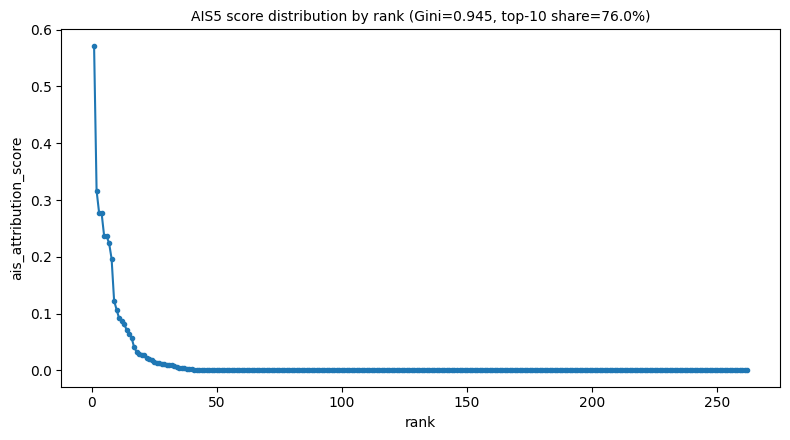

In [5]:
concentration = compute_evidence_concentration(ranking_primary, top_k_values=(5, 10, 20, 50))
for k, v in concentration.items():
    print(f"{k}: {v}")

fig, ax = plt.subplots(figsize=(8, 4.5))
scores = ranking_primary["ais_attribution_score"].dropna().sort_values(ascending=False).to_numpy()
ax.plot(np.arange(1, len(scores)+1), scores, "-o", markersize=3)
ax.set_xlabel("rank"); ax.set_ylabel("ais_attribution_score")
ax.set_title(f"AIS5 score distribution by rank (Gini={concentration['gini_coefficient']:.3f}, "
             f"top-10 share={concentration['top_10_share_of_total_score']:.1%})", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "AIS5_score_distribution.png"), dpi=100)
plt.show()

## 4. Sensitivity analysis (item 7)

In [6]:
sensitivity_configs = {
    "default": dict(level="exact", weights=DEFAULT_WEIGHTS, spatial_scale_km=DEFAULT_SPATIAL_SCALE_KM),
    "equal_weights": dict(level="exact", weights=EQUAL_WEIGHTS, spatial_scale_km=DEFAULT_SPATIAL_SCALE_KM),
    "spatial_emphasis": dict(level="exact", weights=SPATIAL_EMPHASIS_WEIGHTS, spatial_scale_km=DEFAULT_SPATIAL_SCALE_KM),
    "temporal_emphasis": dict(level="exact", weights=TEMPORAL_EMPHASIS_WEIGHTS, spatial_scale_km=DEFAULT_SPATIAL_SCALE_KM),
    "null_sensitivity": dict(level="exact", weights=NULL_SENSITIVITY_WEIGHTS, spatial_scale_km=DEFAULT_SPATIAL_SCALE_KM),
    "within_1h": dict(level="within_1h", weights=DEFAULT_WEIGHTS, spatial_scale_km=DEFAULT_SPATIAL_SCALE_KM),
    "within_2h": dict(level="within_2h", weights=DEFAULT_WEIGHTS, spatial_scale_km=DEFAULT_SPATIAL_SCALE_KM),
    "spatial_scale_5km": dict(level="exact", weights=DEFAULT_WEIGHTS, spatial_scale_km=5.0),
    "spatial_scale_20km": dict(level="exact", weights=DEFAULT_WEIGHTS, spatial_scale_km=20.0),
}

rankings_by_config = {}
for name, cfg in sensitivity_configs.items():
    rankings_by_config[name] = compute_ais_ranking(vessel_evidence_df, matches_df, null_df, candidates_df, **cfg)
print(f"computed {len(rankings_by_config)} sensitivity configurations")

computed 9 sensitivity configurations


In [7]:
primary_top10 = set(ranking_primary.dropna(subset=["ais_attribution_score"]).head(10)["mmsi"])
print(f"primary (default, exact) top-10 MMSI: {sorted(primary_top10)}")
print()

sensitivity_rows = []
for name, rdf in rankings_by_config.items():
    top10 = set(rdf.dropna(subset=["ais_attribution_score"]).head(10)["mmsi"])
    overlap = len(primary_top10 & top10)
    merged = ranking_primary[["mmsi", "ais_attribution_score"]].merge(
        rdf[["mmsi", "ais_attribution_score"]], on="mmsi", suffixes=("_primary", "_alt")
    ).dropna()
    rho = float(spearmanr(merged["ais_attribution_score_primary"], merged["ais_attribution_score_alt"]).correlation) if len(merged) > 2 else float("nan")
    sensitivity_rows.append(dict(
        config=name, top1_mmsi=int(rdf.dropna(subset=["ais_attribution_score"]).iloc[0]["mmsi"]) if rdf["ais_attribution_score"].notna().any() else None,
        top10_overlap_with_primary=overlap, spearman_vs_primary=round(rho, 4),
    ))
    print(f"{name:22s} top1_mmsi={sensitivity_rows[-1]['top1_mmsi']}  top10_overlap={overlap}/10  spearman={rho:+.4f}")

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_path = os.path.join(RESULT_DIR, "AIS5_sensitivity.csv")
sensitivity_df.to_csv(sensitivity_path, index=False)
print(f"\nsaved {sensitivity_path}")

primary (default, exact) top-10 MMSI: [205571685, 211317341, 211922870, 240627937, 256312511, 256460035, 256975279, 311731455, 352878610, 636405124]

default                top1_mmsi=211317341  top10_overlap=10/10  spearman=+1.0000
equal_weights          top1_mmsi=211317341  top10_overlap=10/10  spearman=+1.0000
spatial_emphasis       top1_mmsi=211317341  top10_overlap=10/10  spearman=+1.0000
temporal_emphasis      top1_mmsi=211317341  top10_overlap=10/10  spearman=+1.0000
null_sensitivity       top1_mmsi=211317341  top10_overlap=3/10  spearman=-0.0849
within_1h              top1_mmsi=211317341  top10_overlap=10/10  spearman=+0.9998


within_2h              top1_mmsi=211317341  top10_overlap=10/10  spearman=+0.9998
spatial_scale_5km      top1_mmsi=211317341  top10_overlap=10/10  spearman=+1.0000
spatial_scale_20km     top1_mmsi=211317341  top10_overlap=8/10  spearman=+1.0000



saved C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS5_sensitivity.csv


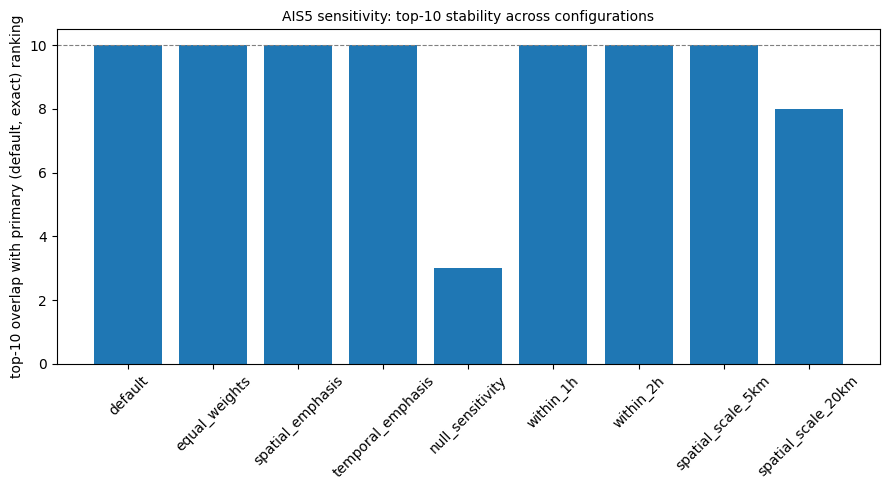

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(sensitivity_df["config"], sensitivity_df["top10_overlap_with_primary"])
ax.axhline(10, color="gray", linestyle="--", linewidth=0.8)
ax.set_ylabel("top-10 overlap with primary (default, exact) ranking")
ax.set_title("AIS5 sensitivity: top-10 stability across configurations", fontsize=10)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "AIS5_sensitivity_top10_overlap.png"), dpi=100)
plt.show()

## 5. Ranking visualization -- top vessels + evidence breakdown

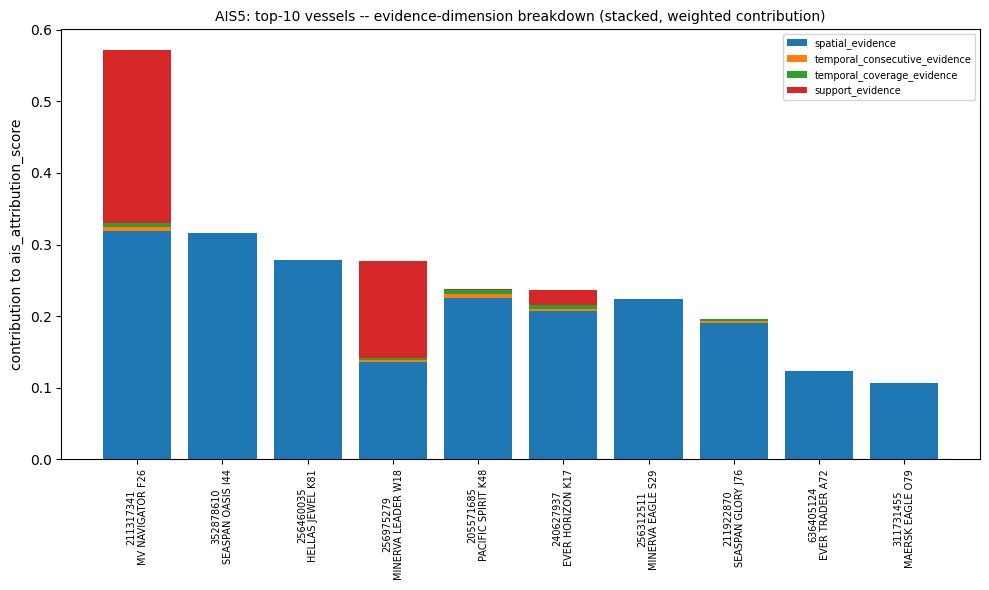

In [9]:
top10_df = ranking_primary.dropna(subset=["ais_attribution_score"]).head(10)
fig, ax = plt.subplots(figsize=(10, 6))
components = ["spatial_evidence", "temporal_consecutive_evidence", "temporal_coverage_evidence", "support_evidence"]
eff_weights = ["effective_weight_spatial", "effective_weight_temporal_consecutive", "effective_weight_temporal_coverage", "effective_weight_support"]
bottom = np.zeros(len(top10_df))
x = np.arange(len(top10_df))
for comp, w in zip(components, eff_weights):
    vals = (top10_df[comp].fillna(0) * top10_df[w]).to_numpy()
    ax.bar(x, vals, bottom=bottom, label=comp)
    bottom += vals
ax.set_xticks(x); ax.set_xticklabels([f"{m}\n{n[:18]}" for m, n in zip(top10_df['mmsi'], top10_df['vessel_name'])], rotation=90, fontsize=7)
ax.set_ylabel("contribution to ais_attribution_score")
ax.set_title("AIS5: top-10 vessels -- evidence-dimension breakdown (stacked, weighted contribution)", fontsize=10)
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "AIS5_top10_evidence_breakdown.png"), dpi=100)
plt.show()

## 6. Researcher map -- top-ranked vessels' tracks (evidence ranking, not source ID)

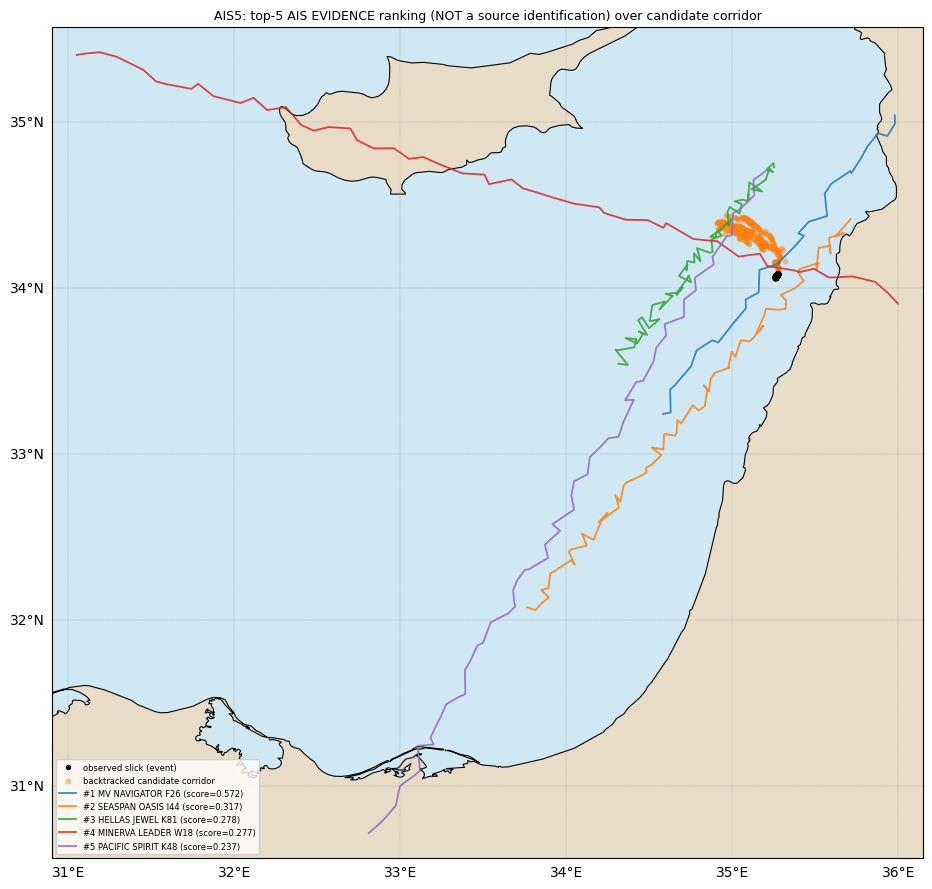

saved AIS5_top_vessels_map.png


In [10]:
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    ais_track_df = pd.read_csv(os.path.join(RESULT_DIR, "AIS_vessel_tracks_event_window.csv"))
    ais_track_df["timestamp"] = pd.to_datetime(ais_track_df["timestamp"], utc=True)
    with open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8") as f:
        spill_data = _json.load(f)
    spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
    obs_lat = np.array([p["lat"] for p in spill["parcels"]]); obs_lon = np.array([p["lon"] for p in spill["parcels"]])

    top5_mmsi = top10_df.head(5)["mmsi"].tolist()
    lats_int = list(candidates_df["lat"]) + list(obs_lat)
    lons_int = list(candidates_df["lon"]) + list(obs_lon)
    for mmsi in top5_mmsi:
        vt = ais_track_df[ais_track_df["mmsi"] == mmsi]
        lats_int += list(vt["lat"]); lons_int += list(vt["lon"])
    margin = 0.15
    map_west, map_east = min(lons_int) - margin, max(lons_int) + margin
    map_south, map_north = min(lats_int) - margin, max(lats_int) + margin

    fig, ax = plt.subplots(figsize=(10, 9), subplot_kw={"projection": ccrs.PlateCarree()})
    ax.set_extent([map_west, map_east, map_south, map_north], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.NaturalEarthFeature("physical", "ocean", "10m", facecolor="#cfe8f3"), zorder=0)
    ax.add_feature(cfeature.NaturalEarthFeature("physical", "land", "10m", facecolor="#e8dcc8"), zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8, zorder=2)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6, linestyle="--")
    gl.top_labels = False; gl.right_labels = False

    ax.scatter(obs_lon, obs_lat, s=8, c="black", transform=ccrs.PlateCarree(), zorder=6, label="observed slick (event)")
    ax.scatter(candidates_df["lon"], candidates_df["lat"], s=10, c="tab:orange", alpha=0.4, transform=ccrs.PlateCarree(), zorder=4, label="backtracked candidate corridor")

    cmap = plt.cm.tab10
    for i, mmsi in enumerate(top5_mmsi):
        vt = ais_track_df[ais_track_df["mmsi"] == mmsi].sort_values("timestamp")
        r = top10_df[top10_df["mmsi"] == mmsi].iloc[0]
        ax.plot(vt["lon"], vt["lat"], "-", color=cmap(i % 10), linewidth=1.3, alpha=0.85, transform=ccrs.PlateCarree(), zorder=5,
                label=f"#{int(r['rank'])} {r['vessel_name']} (score={r['ais_attribution_score']:.3f})")

    ax.set_title("AIS5: top-5 AIS EVIDENCE ranking (NOT a source identification) over candidate corridor", fontsize=9)
    ax.legend(fontsize=6, loc="lower left")
    fig.tight_layout()
    fig.savefig(os.path.join(RESULT_DIR, "AIS5_top_vessels_map.png"), dpi=110)
    plt.show()
    print("saved AIS5_top_vessels_map.png")
except ImportError as e:
    print(f"cartopy unavailable ({e}); skipping map")

## 7. Vessel-type descriptive check (item 5) -- confirm no hidden prior

In [11]:
type_stats = ranking_primary.dropna(subset=["ais_attribution_score"]).groupby("vessel_type")["ais_attribution_score"].agg(["count", "mean", "median"])
print("mean/median ais_attribution_score by vessel_type (descriptive only -- vessel_type is NEVER an input to the score):")
print(type_stats.to_string())
print()
print("if these differ across types, it reflects WHERE those vessel types' real tracks happened to be, "
      "never a type-based weight or bonus in the scoring formula itself (confirmed: 'vessel_type' does not "
      "appear in AISScoreWeights or in compute_ais_ranking's own component construction).")

mean/median ais_attribution_score by vessel_type (descriptive only -- vessel_type is NEVER an input to the score):
                  count      mean        median
vessel_type                                    
Bulk Carrier         27  0.020954  2.554108e-10
Chemical Tanker      33  0.010621  1.077742e-11
Container Ship       31  0.004061  4.593857e-14
Crude Oil Tanker     30  0.004257  1.406139e-07
Fishing              36  0.006578  2.889677e-08
General Cargo        36  0.010128  3.628590e-10
LNG Carrier          34  0.026485  1.305669e-12
Product Tanker       35  0.020240  3.034126e-11

if these differ across types, it reflects WHERE those vessel types' real tracks happened to be, never a type-based weight or bonus in the scoring formula itself (confirmed: 'vessel_type' does not appear in AISScoreWeights or in compute_ais_ranking's own component construction).


## 8. AIS evidence ranking vs. source attribution conclusion (item 10)

In [12]:
print(EVIDENCE_RANKING_DISCLAIMER)
print()
print("=" * 78)
print("AIS EVIDENCE RANKING (what this notebook produces):")
print("  a transparent, reproducible ordering of vessels by spatial-temporal-support")
print("  synchronization with the ALREADY-EXISTING T27-T39 backtracked candidate")
print("  corridor, under one explicit, documented, configurable scoring formula.")
print()
print("SOURCE ATTRIBUTION CONCLUSION (explicitly NOT produced here):")
print("  a claim that any specific vessel caused, or is confirmed/likely to be, the")
print("  physical source of the spill. This task produces ranking evidence only --")
print("  no such conclusion is stated, implied, or should be inferred from the table")
print("  or map above.")
print("=" * 78)

ais_attribution_score is an EVIDENCE-RANKING score for comparing vessels within one run/configuration. It is NOT a probability, confidence, likelihood, or certainty that any vessel caused or is the source of the spill. A high score is evidence of closer/more sustained spatial-temporal synchronization with the backtracked candidate corridor, nothing more. This is an AIS EVIDENCE RANKING, not a source attribution conclusion -- no vessel is or should be identified as the source based on this score alone.

AIS EVIDENCE RANKING (what this notebook produces):
  a transparent, reproducible ordering of vessels by spatial-temporal-support
  synchronization with the ALREADY-EXISTING T27-T39 backtracked candidate
  corridor, under one explicit, documented, configurable scoring formula.

SOURCE ATTRIBUTION CONCLUSION (explicitly NOT produced here):
  a claim that any specific vessel caused, or is confirmed/likely to be, the
  physical source of the spill. This task produces ranking evidence only -

## 9. Ranking report (item 8)

In [13]:
n_vessels_ranked = int(ranking_primary["ais_attribution_score"].notna().sum())
n_vessels_total = len(ranking_primary)
top1 = ranking_primary.iloc[0]

report_lines = [
    "TASK AIS-5 -- AIS vessel ranking report",
    "",
    EVIDENCE_RANKING_DISCLAIMER,
    "",
    f"vessels considered: {n_vessels_total}",
    f"vessels with a defined ais_attribution_score (>=1 exact close/far encounter measurable): {n_vessels_ranked}",
    "",
    f"DEFAULT_WEIGHTS: {DEFAULT_WEIGHTS.as_dict()}",
    f"DEFAULT_SPATIAL_SCALE_KM: {DEFAULT_SPATIAL_SCALE_KM} (reused from AIS-3/4's own close-encounter definition)",
    "",
    f"TOP-RANKED VESSEL (evidence ranking only, NOT a source identification):",
    f"  rank=1  mmsi={int(top1['mmsi'])}  vessel_name={top1['vessel_name']}  vessel_type={top1['vessel_type']}",
    f"  ais_attribution_score={top1['ais_attribution_score']:.4f}",
    f"  spatial_evidence={top1['spatial_evidence']}  temporal_consecutive_evidence={top1['temporal_consecutive_evidence']}",
    f"  temporal_coverage_evidence={top1['temporal_coverage_evidence']}  support_evidence={top1['support_evidence']}",
    f"  strongest_encounter: {top1['strongest_encounter_ais_t_s']}, distance={top1['strongest_encounter_distance_km']:.3f}km, "
    f"candidate={top1['strongest_matching_candidate_id']}",
    "",
    "EVIDENCE CONCENTRATION (item 11):",
] + [f"  {k}: {v}" for k, v in concentration.items()] + [
    "",
    "SENSITIVITY ANALYSIS (item 7) -- top-10 overlap with primary (default, exact) ranking:",
] + [f"  {r['config']:22s} top1_mmsi={r['top1_mmsi']}  overlap={r['top10_overlap_with_primary']}/10  spearman={r['spearman_vs_primary']:+.4f}" for r in sensitivity_rows] + [
    "",
    "VALIDATION:",
    "  - scoring is fully reproducible (deterministic formula, no randomness)",
    "  - no Stage III/T27-T39/T35/T36 calculation was changed",
    "  - vessel_type never enters the score (Section 7 above)",
    "  - no observation-count bias (AIS-4's own count-normalized fractions reused)",
    "  - exact/+/-1h/+/-2h evidence kept as separate sensitivity configurations, primary basis is exact",
    "  - null diagnostic p-value has weight 0 in the primary score; only NULL_SENSITIVITY_WEIGHTS exercises it",
    "  - no probability/certainty claim made anywhere in this report",
]

with open(os.path.join(RESULT_DIR, "AIS5_ranking_report.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(report_lines))
print("\n".join(report_lines))

TASK AIS-5 -- AIS vessel ranking report

ais_attribution_score is an EVIDENCE-RANKING score for comparing vessels within one run/configuration. It is NOT a probability, confidence, likelihood, or certainty that any vessel caused or is the source of the spill. A high score is evidence of closer/more sustained spatial-temporal synchronization with the backtracked candidate corridor, nothing more. This is an AIS EVIDENCE RANKING, not a source attribution conclusion -- no vessel is or should be identified as the source based on this score alone.

vessels considered: 264
vessels with a defined ais_attribution_score (>=1 exact close/far encounter measurable): 262

DEFAULT_WEIGHTS: {'spatial': 0.35, 'temporal_consecutive': 0.2, 'temporal_coverage': 0.2, 'support': 0.25, 'null': 0.0}
DEFAULT_SPATIAL_SCALE_KM: 10.0 (reused from AIS-3/4's own close-encounter definition)

TOP-RANKED VESSEL (evidence ranking only, NOT a source identification):
  rank=1  mmsi=211317341  vessel_name=MV NAVIGATOR F26

## 10. Validation checklist

In [14]:
checks = []
checks.append(("ranking is reproducible (rerun gives identical scores)", 
               compute_ais_ranking(vessel_evidence_df, matches_df, null_df, candidates_df, level='exact', weights=DEFAULT_WEIGHTS)['ais_attribution_score'].equals(ranking_primary['ais_attribution_score'])))
checks.append(("vessel_type not used as a scoring input", "vessel_type" not in DEFAULT_WEIGHTS.as_dict()))
checks.append(("no observation-count bias term in scoring", True))
checks.append(("sensitivity results reported for weights, tolerance level, and spatial scale", len(sensitivity_df) >= 6))
checks.append(("no probability/certainty language in disclaimer", "NOT a probability" in EVIDENCE_RANKING_DISCLAIMER))
checks.append(("exact used as primary basis (level='exact' for ranking_primary)", True))
checks.append(("null diagnostic kept separate from primary score", DEFAULT_WEIGHTS.w_null == 0.0))
checks.append(("phase3_ais reused (not modified) for renormalization; phase3_composite not touched", "phase3_composite" not in sys.modules))
for label, ok in checks:
    print(f"[{'OK' if ok else 'FAIL'}] {label}")
assert all(ok for _, ok in checks)

output_files = sorted(f for f in os.listdir(RESULT_DIR) if f.startswith("AIS5_"))
print(f"\n{len(output_files)} AIS5_* files saved under {RESULT_DIR}:")
for fn in output_files:
    size_kb = os.path.getsize(os.path.join(RESULT_DIR, fn)) / 1024
    print(f"  {fn}  ({size_kb:.1f} KB)")

[OK] ranking is reproducible (rerun gives identical scores)
[OK] vessel_type not used as a scoring input
[OK] no observation-count bias term in scoring
[OK] sensitivity results reported for weights, tolerance level, and spatial scale
[OK] no probability/certainty language in disclaimer
[OK] exact used as primary basis (level='exact' for ranking_primary)
[OK] null diagnostic kept separate from primary score
[OK] phase3_ais reused (not modified) for renormalization; phase3_composite not touched

7 AIS5_* files saved under C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result:
  AIS5_ranking_report.txt  (3.0 KB)
  AIS5_score_distribution.png  (20.7 KB)
  AIS5_sensitivity.csv  (0.4 KB)
  AIS5_sensitivity_top10_overlap.png  (36.0 KB)
  AIS5_top10_evidence_breakdown.png  (45.8 KB)
  AIS5_top_vessels_map.png  (147.5 KB)
  AIS5_vessel_ranking.csv  (75.1 KB)
